# 지하철 이용승객 데이터 - 비모수 검정 & 상관분석

## 0. 라이브러리

In [1]:
import pandas as pd
import os
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


## 1. 데이터 불러오기 및 전처리

In [2]:
dirpath = './rawfiles/'
files = [f for f in os.listdir(dirpath) if f.startswith('CARD_SUBWAY')]

raw = pd.DataFrame()
for f in files:
    raw = pd.concat([raw, pd.read_csv(dirpath + f, encoding='utf-8-sig')], axis=0)
raw = raw.reset_index(drop=True)

raw['사용일자'] = pd.to_datetime(raw['사용일자'], format='%Y%m%d')
conv = {0:'월', 1:'화', 2:'수', 3:'목', 4:'금', 5:'토', 6:'일'}
raw['요일'] = raw['사용일자'].dt.dayofweek.map(conv)
raw['연월'] = raw['사용일자'].dt.strftime('%Y-%m')
raw['승하차총승객수'] = raw['승차총승객수'] + raw['하차총승객수']

# 일자별 전체 역 합산 (요일/월별 비교에 사용)
daily = raw.groupby('사용일자').agg(승하차총승객수=('승하차총승객수','sum')).reset_index()
daily['요일'] = daily['사용일자'].dt.dayofweek.map(conv)
daily['연월'] = daily['사용일자'].dt.strftime('%Y-%m')
daily['구분'] = daily['요일'].map(lambda d: '주말' if d in ['토','일'] else '평일')
daily.head()


,사용일자,승하차총승객수,요일,연월,구분
0,2019-01-01,6813453.0,화,2019-01,평일
1,2019-01-02,15214002.0,수,2019-01,평일
2,2019-01-03,15716213.0,목,2019-01,평일
3,2019-01-04,16509281.0,금,2019-01,평일
4,2019-01-05,12092335.0,토,2019-01,주말


## 2. 정규성 검정 (Shapiro-Wilk)
H0: 정규분포를 따른다 / H1: 정규분포를 따르지 않는다

In [3]:
stat, p = stats.shapiro(daily['승하차총승객수'])
print(f'Shapiro-Wilk W={stat:.4f}, p={p:.2e}')
print('→ p < 0.05 이므로 정규분포를 따르지 않음 → 비모수 검정 사용')


Shapiro-Wilk W=0.8232, p=1.52e-13
→ p < 0.05 이므로 정규분포를 따르지 않음 → 비모수 검정 사용


## Q1) 2019.01~06 중 목요일에 지하철 승객수가 많은가?
- 먼저 요일 7그룹 전체 차이를 Kruskal-Wallis로 확인
- 유의하면 목요일 vs 나머지 요일을 Mann-Whitney U로 확인

In [4]:
weekday_order = ['월','화','수','목','금','토','일']
groups = [daily.loc[daily['요일']==d, '승하차총승객수'] for d in weekday_order]

h, p = stats.kruskal(*groups)
print(f'Kruskal-Wallis H={h:.2f}, p={p:.2e}')

thu = daily.loc[daily['요일']=='목', '승하차총승객수']
other = daily.loc[daily['요일']!='목', '승하차총승객수']
u, p2 = stats.mannwhitneyu(thu, other, alternative='two-sided')
print(f'목요일 vs 그 외 Mann-Whitney U={u:.1f}, p={p2:.4f}')
print(f"목요일 중앙값={thu.median():,.0f} / 그 외 요일 중앙값={other.median():,.0f}")


Kruskal-Wallis H=111.05, p=1.23e-21
목요일 vs 그 외 Mann-Whitney U=2784.0, p=0.0019
목요일 중앙값=16,990,682 / 그 외 요일 중앙값=16,049,292


**결론**: 요일 간 승객수는 유의한 차이를 보인다 (Kruskal-Wallis, p<0.05). 목요일 승객수는 그 외 요일보다 유의하게 많다 (Mann-Whitney U, p<0.05).

## Q2) 1~6월 중 5월에 승객수가 많은가?

In [5]:
may = daily.loc[daily['연월']=='2019-05', '승하차총승객수']
rest = daily.loc[daily['연월']!='2019-05', '승하차총승객수']
u3, p3 = stats.mannwhitneyu(may, rest, alternative='two-sided')
print(f'5월 vs 그 외 Mann-Whitney U={u3:.1f}, p={p3:.4f}')
print(f"5월 중앙값={may.median():,.0f} / 그 외 월 중앙값={rest.median():,.0f}")


5월 vs 그 외 Mann-Whitney U=3110.0, p=0.0031
5월 중앙값=17,097,938 / 그 외 월 중앙값=16,134,964


**결론**: 5월 승객수는 그 외 월보다 유의하게 많다 (Mann-Whitney U, p<0.05).

## Q3) 1호선과 2호선의 승객수에 차이가 있는가?

In [6]:
line_daily = raw.groupby(['사용일자','노선명'])['승하차총승객수'].sum().reset_index()
l1 = line_daily.loc[line_daily['노선명']=='1호선', '승하차총승객수']
l2 = line_daily.loc[line_daily['노선명']=='2호선', '승하차총승객수']
u4, p4 = stats.mannwhitneyu(l1, l2, alternative='two-sided')
print(f'1호선 vs 2호선 Mann-Whitney U={u4:.1f}, p={p4:.2e}')
print(f"1호선 중앙값={l1.median():,.0f} / 2호선 중앙값={l2.median():,.0f}")


1호선 vs 2호선 Mann-Whitney U=5035.0, p=4.36e-30
1호선 중앙값=2,582,999 / 2호선 중앙값=3,796,957


**결론**: 2호선 승객수는 1호선의 승객수보다 유의하게 많다 (독립표본검정/Mann-Whitney U, p<0.05).

## Q4, 추가 문제) 평일과 주말의 지하철 이용객수에 유의한 차이가 있는가?

In [7]:
wd = daily.loc[daily['구분']=='평일', '승하차총승객수']
we = daily.loc[daily['구분']=='주말', '승하차총승객수']
u5, p5 = stats.mannwhitneyu(wd, we, alternative='two-sided')
print(f'평일 vs 주말 Mann-Whitney U={u5:.1f}, p={p5:.2e}')
print(f"평일 중앙값={wd.median():,.0f} / 주말 중앙값={we.median():,.0f}")


평일 vs 주말 Mann-Whitney U=6413.0, p=8.91e-22
평일 중앙값=16,729,498 / 주말 중앙값=10,623,230


**결론**: 평일 승객수는 주말보다 유의하게 많다 (Mann-Whitney U, p<0.05).

## Q5, 추가 문제) 선릉역과 어린이대공원역의 승객수에 차이가 있는가?
- Wilcoxon signed-rank test

In [8]:
seolleung = raw[raw['역명'].str.startswith('선릉', na=False)].groupby('사용일자')['승하차총승객수'].sum()
children = raw[raw['역명'].str.startswith('어린이대공원', na=False)].groupby('사용일자')['승하차총승객수'].sum()
common = seolleung.index.intersection(children.index)

w, pw = stats.wilcoxon(seolleung[common], children[common])
print(f'선릉 vs 어린이대공원 Wilcoxon W={w:.1f}, p={pw:.2e}, n={len(common)}')
print(f"선릉 중앙값={seolleung[common].median():,.0f} / 어린이대공원 중앙값={children[common].median():,.0f}")


선릉 vs 어린이대공원 Wilcoxon W=4.0, p=2.00e-31, n=181
선릉 중앙값=164,684 / 어린이대공원 중앙값=31,894


**결론**: 선릉역 승객수는 어린이대공원역보다 유의하게 많다 (대응표본검정/Wilcoxon signed-rank, p<0.05).

## Q6) 상관분석: 승차총승객수와 하차총승객수는 상관관계가 있는가?

- 정규성을 만족하지 않으므로 비모수적 방법인 Spearman 순위상관계수 사용

Spearman r=0.9921, p=0.00e+00


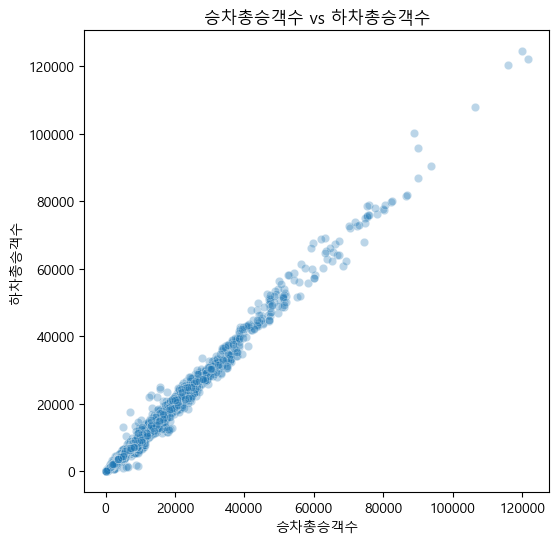

In [9]:
corr, pc = stats.spearmanr(raw['승차총승객수'], raw['하차총승객수'])
print(f'Spearman r={corr:.4f}, p={pc:.2e}')

plt.figure(figsize=(6,6))
sns.scatterplot(data=raw.sample(3000, random_state=1), x='승차총승객수', y='하차총승객수', alpha=0.3)
plt.title('승차총승객수 vs 하차총승객수')
plt.show()


**결론**: 승차총승객수와 하차총승객수는 강한 양의 상관관계를 보인다 (Spearman r≈0.99, p<0.05) — 한 변수로 다른 변수를 예측하는 것이 가능할 정도로 밀접함.

## 요약
| 질문 | 검정 방법 | 결과 |
|---|---|---|
| 목요일 승객수가 많은가 | Kruskal-Wallis + Mann-Whitney U | 유의함 (p<0.05), 목요일이 더 많음 |
| 5월 승객수가 많은가 | Mann-Whitney U | 유의함 (p<0.05), 5월이 더 많음 |
| 1호선 vs 2호선 | Mann-Whitney U | 유의함 (p<0.05), 2호선이 더 많음 |
| 평일 vs 주말 | Mann-Whitney U | 유의함 (p<0.05), 평일이 더 많음 |
| 선릉역 vs 어린이대공원역 | Wilcoxon signed-rank (대응) | 유의함 (p<0.05), 선릉역이 더 많음 |
| 승차 vs 하차 상관 | Spearman 상관분석 | r≈0.99, 강한 양의 상관 |
